# Retail Orders: Data Profiling & Quality Checks

RabTech Academy internship deliverable. This notebook profiles the provided retail orders CSV, executes data-quality checks, and exports a results report.

**Important:** checks flag problems; they do not silently repair source data. Resolve issues with the data owner before publishing official KPIs.


In [20]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Task 04 - EDA started successfully!")


Task 04 - EDA started successfully!


In [21]:

df = pd.read_csv("retail-orders-raw.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())


Dataset loaded successfully!
Number of rows and columns: (12, 9)


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2,799,10.0,Paid
1,RT-1002,03/01/2026,Fresher,Bengaluru,Course Access,1,1499,0.0,paid
2,RT-1003,2026-01-05,student,Chennai,Course Access,1,1499,NaN,Pending
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid
4,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid


In [22]:

# Step 3: Descriptive Statistics

print("Dataset Shape:", df.shape)

print("\n--- Numerical Summary ---")
display(df.describe().T)

print("\n--- Median Values ---")
display(df.select_dtypes(include="number").median())

print("\n--- Missing Values ---")
display(df.isnull().sum())

print("\n--- Duplicate Rows ---")
print("Duplicate rows:", df.duplicated().sum())



Dataset Shape: (12, 9)

--- Numerical Summary ---


,count,mean,std,min,25%,50%,75%,max
unit_price,12.0,1082.333333,318.614425,799.0,799.0,999.0,1499.0,1499.0
discount_pct,11.0,13.636364,30.748245,0.0,0.0,5.0,10.0,105.0



--- Median Values ---


,0
unit_price,999.0
discount_pct,5.0



--- Missing Values ---


,0
order_id,0
order_date,1
customer_segment,0
city,1
category,0
quantity,0
unit_price,0
discount_pct,1
payment_status,0



--- Duplicate Rows ---
Duplicate rows: 1


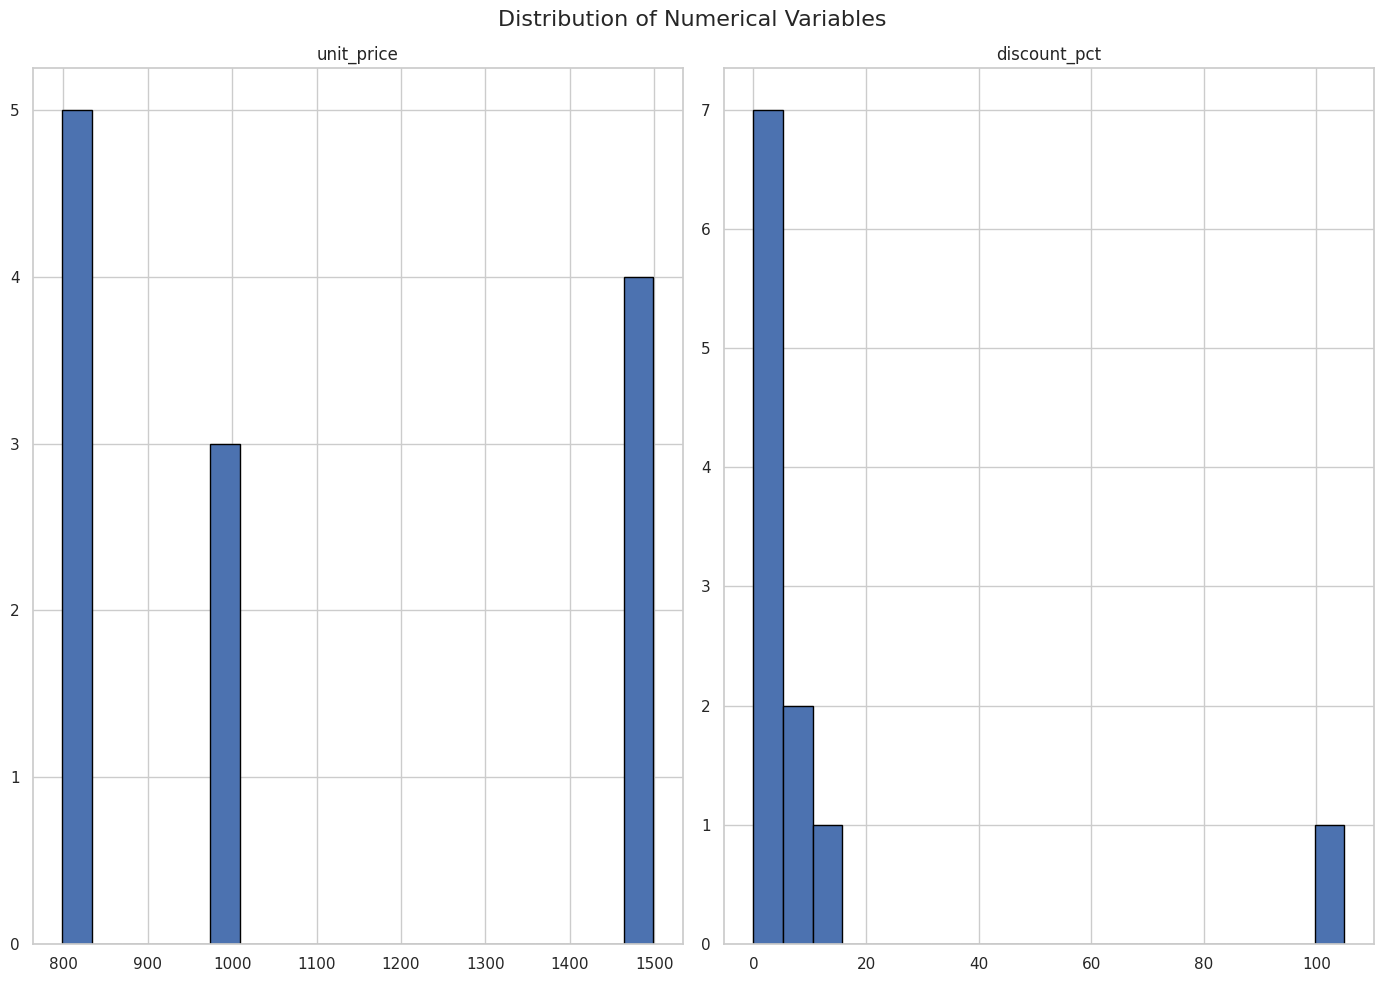

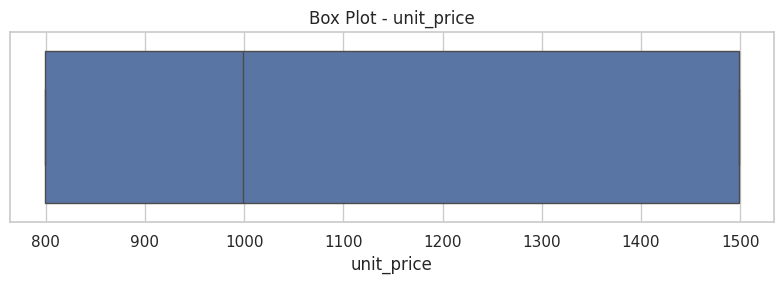

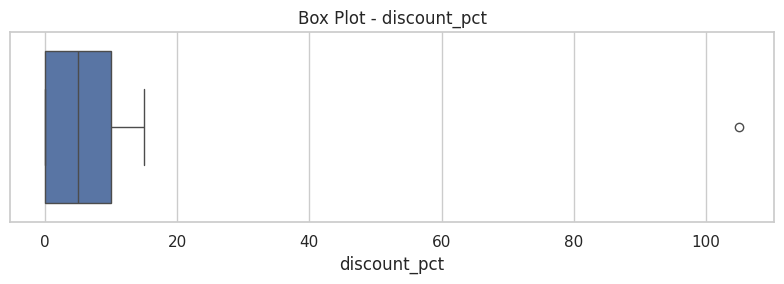

In [23]:

# Step 4: Histograms and Box Plots

numeric_df = df.select_dtypes(include="number")

# Histograms
numeric_df.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Distribution of Numerical Variables", fontsize=16)
plt.tight_layout()
plt.show()

# Box plots to identify outliers
for column in numeric_df.columns[:6]:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=numeric_df[column])
    plt.title(f"Box Plot - {column}")
    plt.tight_layout()
    plt.show()


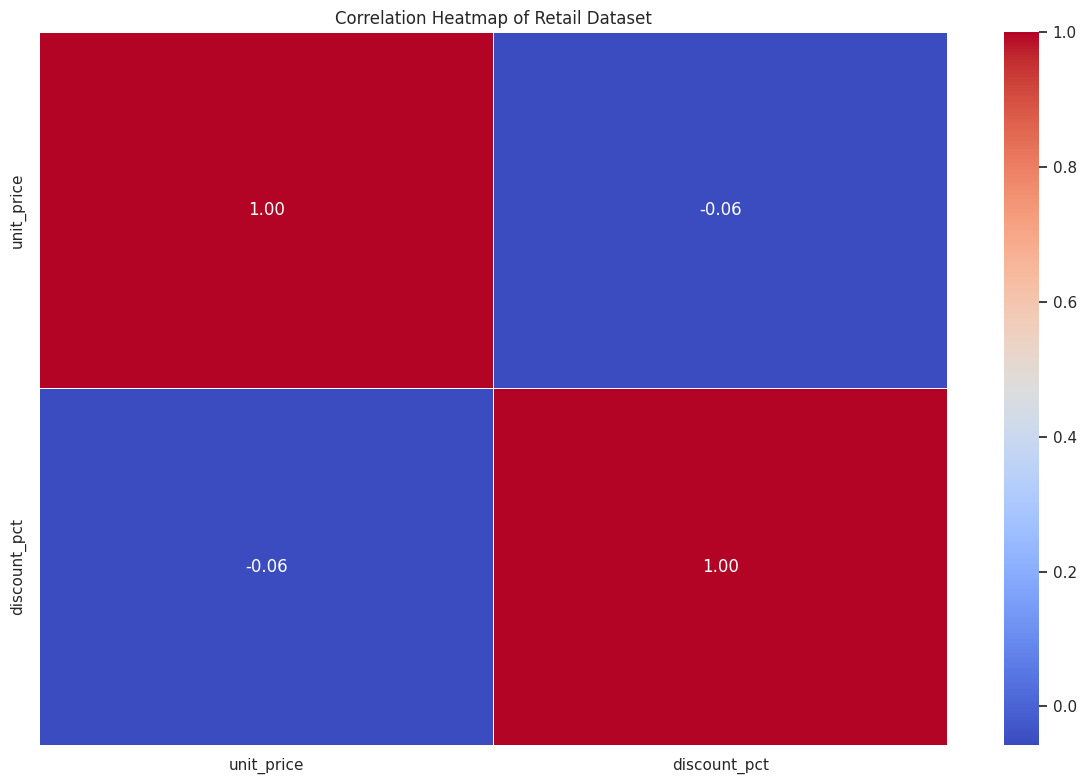

In [24]:

# Step 5: Correlation Heatmap

numeric_df = df.select_dtypes(include="number")

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Retail Dataset")
plt.tight_layout()
plt.show()


In [26]:

# Step 6: Business Hypothesis Testing

from scipy.stats import pearsonr, ttest_ind

numeric_df = df.select_dtypes(include="number")

print("Available numerical columns:")
print(numeric_df.columns.tolist())


Available numerical columns:
['unit_price', 'discount_pct']


In [27]:

print("All columns in the dataset:")
for col in df.columns:
    print(col)


All columns in the dataset:
order_id
order_date
customer_segment
city
category
quantity
unit_price
discount_pct
payment_status


In [28]:

# Step 8: Initial Business Insights

print("===== RETAIL DATA ANALYSIS =====")

print(f"Total records: {df.shape[0]}")
print(f"Total columns: {df.shape[1]}")

print("\n1. Missing Values")
print("Total missing cells:", df.isnull().sum().sum())

print("\n2. Duplicate Records")
print("Total duplicates:", df.duplicated().sum())

print("\n3. Numerical Insights")
display(df.describe().T)

print("\n4. Unique Values in Each Column")
display(df.nunique().to_frame("Unique Values"))


===== RETAIL DATA ANALYSIS =====
Total records: 12
Total columns: 9

1. Missing Values
Total missing cells: 3

2. Duplicate Records
Total duplicates: 1

3. Numerical Insights


,count,mean,std,min,25%,50%,75%,max
unit_price,12.0,1082.333333,318.614425,799.0,799.0,999.0,1499.0,1499.0
discount_pct,11.0,13.636364,30.748245,0.0,0.0,5.0,10.0,105.0



4. Unique Values in Each Column


,Unique Values
order_id,11
order_date,10
customer_segment,4
city,7
category,3
quantity,5
unit_price,3
discount_pct,5
payment_status,5


In [30]:

# Step 9: Top 5 Data Findings

print("TOP 5 FINDINGS FROM RETAIL DATA ANALYSIS")
print("=" * 45)

print(f"1. The dataset contains {df.shape[0]} records and {df.shape[1]} columns.")

missing = df.isnull().sum().sum()
print(f"2. The dataset contains {missing} missing cells.")

duplicates = df.duplicated().sum()
print(f"3. The dataset contains {duplicates} duplicate rows.")

numeric_df = df.select_dtypes(include="number")

if not numeric_df.empty:
    print("4. Numerical columns with the highest variability:")
    print(numeric_df.std().sort_values(ascending=False).head(3))

    print("\n5. Numerical columns with the highest average values:")
    print(numeric_df.mean().sort_values(ascending=False).head(3))
else:
    print("4. No numerical columns are available.")
    print("5. Convert relevant columns to numeric for further analysis.")


TOP 5 FINDINGS FROM RETAIL DATA ANALYSIS
1. The dataset contains 12 records and 9 columns.
2. The dataset contains 3 missing cells.
3. The dataset contains 1 duplicate rows.
4. Numerical columns with the highest variability:
unit_price      318.614425
discount_pct     30.748245
dtype: float64

5. Numerical columns with the highest average values:
unit_price      1082.333333
discount_pct      13.636364
dtype: float64


## 1. Upload the dataset
Run this cell in Google Colab and upload `retail-orders-raw.csv`. If the file is already in the Colab session, you can skip the upload and set `FILE_PATH` to its location.

## Conclusion

Exploratory Data Analysis (EDA) was performed on the retail dataset using Python, Pandas, Matplotlib, and Seaborn.

The analysis included descriptive statistics, missing-value and duplicate checks, histograms, box plots, and a correlation heatmap. These techniques helped examine data distributions, identify potential outliers, and understand relationships between numerical variables.

The statistical summaries and visualizations provide a foundation for identifying business trends and supporting data-driven retail decisions. Further hypothesis testing and interpretation of the results can help validate specific business assumptions.

Overall, this task improved my understanding of data exploration, statistical analysis, and visualization using Python.

In [32]:

print("Dataset columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)


Dataset columns:
['order_id', 'order_date', 'customer_segment', 'city', 'category', 'quantity', 'unit_price', 'discount_pct', 'payment_status']

Data types:
order_id             object
order_date           object
customer_segment     object
city                 object
category             object
quantity             object
unit_price            int64
discount_pct        float64
payment_status       object
dtype: object


In [ ]:
from google.colab import files
uploaded = files.upload()
print('Uploaded files:', list(uploaded.keys()))


Saving retail-orders-raw.csv to retail-orders-raw.csv
Uploaded files: ['retail-orders-raw.csv']


In [33]:

# Task 04: Prepare hypothesis testing

from scipy.stats import pearsonr, ttest_ind, f_oneway

print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())


Dataset shape: (12, 9)

Available columns:
['order_id', 'order_date', 'customer_segment', 'city', 'category', 'quantity', 'unit_price', 'discount_pct', 'payment_status']


In [34]:

# Task 04: Three hypothesis tests

from scipy.stats import pearsonr, ttest_ind, f_oneway

numeric_df = df.select_dtypes(include="number")
categorical_df = df.select_dtypes(exclude="number")

print("HYPOTHESIS TESTING")
print("=" * 40)

# Test 1: Relationship between two numerical variables
if numeric_df.shape[1] >= 2:
    x = numeric_df.iloc[:, 0].dropna()
    y = numeric_df.iloc[:, 1].dropna()
    common = pd.concat([x, y], axis=1).dropna()

    if len(common) >= 3 and common.iloc[:, 0].nunique() > 1 and common.iloc[:, 1].nunique() > 1:
        r, p = pearsonr(common.iloc[:, 0], common.iloc[:, 1])
        print("\nTest 1: Correlation between numerical variables")
        print("Variables:", common.columns.tolist())
        print(f"Correlation: {r:.3f}, p-value: {p:.4f}")
    else:
        print("\nTest 1: Insufficient variation or data.")
else:
    print("\nTest 1: Need at least two numerical columns.")

# Test 2: Compare a numerical variable across two categories
if numeric_df.shape[1] >= 1 and categorical_df.shape[1] >= 1:
    value_col = numeric_df.columns[0]
    group_col = categorical_df.columns[0]
    groups = [
        group[value_col].dropna()
        for _, group in df[[group_col, value_col]].groupby(group_col)
    ]
    groups = [g for g in groups if len(g) >= 2]

    if len(groups) >= 2:
        t, p = ttest_ind(groups[0], groups[1], equal_var=False)
        print(f"\nTest 2: Compare {value_col} across groups in {group_col}")
        print(f"t-statistic: {t:.3f}, p-value: {p:.4f}")
    else:
        print("\nTest 2: Need two groups with at least two values each.")
else:
    print("\nTest 2: Need numerical and categorical columns.")

# Test 3: Compare a numerical variable across three or more groups
if numeric_df.shape[1] >= 1 and categorical_df.shape[1] >= 1:
    value_col = numeric_df.columns[0]
    group_col = categorical_df.columns[0]
    grouped = [
        group[value_col].dropna()
        for _, group in df[[group_col, value_col]].groupby(group_col)
    ]
    grouped = [g for g in grouped if len(g) >= 2]

    if len(grouped) >= 3:
        f, p = f_oneway(*grouped)
        print(f"\nTest 3: Compare {value_col} across categories in {group_col}")
        print(f"F-statistic: {f:.3f}, p-value: {p:.4f}")
    else:
        print("\nTest 3: Need at least three groups with two values each.")
else:
    print("\nTest 3: Need numerical and categorical columns.")


HYPOTHESIS TESTING

Test 1: Correlation between numerical variables
Variables: ['unit_price', 'discount_pct']
Correlation: -0.057, p-value: 0.8683

Test 2: Need two groups with at least two values each.

Test 3: Need at least three groups with two values each.


In [ ]:
import pandas as pd
import numpy as np
from datetime import date
from pathlib import Path

FILE_PATH = 'retail-orders-raw.csv'  # Change this if your uploaded filename differs
df_raw = pd.read_csv(FILE_PATH, dtype={'order_id': 'string', 'quantity': 'string'})
print('Rows, columns:', df_raw.shape)
display(df_raw.head())
display(pd.DataFrame({'column': df_raw.columns, 'dtype': df_raw.dtypes.astype(str).values, 'missing_count': df_raw.isna().sum().values}))


Rows, columns: (12, 9)


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2,799,10.0,Paid
1,RT-1002,03/01/2026,Fresher,Bengaluru,Course Access,1,1499,0.0,paid
2,RT-1003,2026-01-05,student,Chennai,Course Access,1,1499,NaN,Pending
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid
4,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid


,column,dtype,missing_count
0,order_id,string,0
1,order_date,object,1
2,customer_segment,object,0
3,city,object,1
4,category,object,0
5,quantity,string,0
6,unit_price,int64,0
7,discount_pct,float64,1
8,payment_status,object,0


## 2. Data profile
Review missing values, duplicate rows, duplicate order IDs, and raw value distributions.

In [ ]:
profile = pd.DataFrame({
    'column': df_raw.columns,
    'dtype': [str(df_raw[c].dtype) for c in df_raw.columns],
    'non_null_count': [int(df_raw[c].notna().sum()) for c in df_raw.columns],
    'missing_count': [int(df_raw[c].isna().sum()) for c in df_raw.columns],
    'missing_pct': [round(float(df_raw[c].isna().mean() * 100), 2) for c in df_raw.columns],
    'distinct_values': [int(df_raw[c].nunique(dropna=True)) for c in df_raw.columns]
})
display(profile)
print('Exact duplicate rows:', int(df_raw.duplicated().sum()))
print('Duplicate order IDs (all rows with repeated ID):')
display(df_raw[df_raw['order_id'].duplicated(keep=False)].sort_values('order_id'))
for col in ['customer_segment', 'category', 'payment_status']:
    print(f'\\nValues in {col}:')
    display(df_raw[col].value_counts(dropna=False).rename_axis(col).reset_index(name='count'))


,column,dtype,non_null_count,missing_count,missing_pct,distinct_values
0,order_id,string,12,0,0.00,11
1,order_date,object,11,1,8.33,10
2,customer_segment,object,12,0,0.00,4
3,city,object,11,1,8.33,7
4,category,object,12,0,0.00,3
5,quantity,string,12,0,0.00,5
6,unit_price,int64,12,0,0.00,3
7,discount_pct,float64,11,1,8.33,5
8,payment_status,object,12,0,0.00,5


Exact duplicate rows: 1
Duplicate order IDs (all rows with repeated ID):


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid
4,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid


\nValues in customer_segment:


,customer_segment,count
0,Student,4
1,Professional,4
2,Fresher,3
3,student,1


\nValues in category:


,category,count
0,Learning Kit,5
1,Course Access,4
2,Mentor Session,3


\nValues in payment_status:


,payment_status,count
0,Paid,7
1,Pending,2
2,paid,1
3,Failed,1
4,Refunded,1


## 3. Executable data-quality checks
The source dictionary says dates must be ISO dates from 2025-01-01 through today; order IDs are required and unique; quantity is a whole number greater than zero; unit price is non-negative; discount is between 0 and 100; and categories/statuses must map to approved values.

In [ ]:
today = pd.Timestamp(date.today())
checks = []

def add_check(dimension, column, issue, failed_count, total_count, expected_rule, action):
    checks.append({
        'dimension': dimension, 'column': column, 'issue': issue,
        'failed_count': int(failed_count), 'total_count': int(total_count),
        'status': 'PASS' if int(failed_count) == 0 else 'FAIL',
        'expected_rule': expected_rule, 'recommended_action': action
    })

# Completeness
for col in ['order_id', 'order_date', 'customer_segment', 'city', 'category', 'quantity', 'unit_price', 'payment_status']:
    add_check('Completeness', col, 'Required value missing', df_raw[col].isna().sum(), len(df_raw), 'Required fields must be populated', 'Recover from source; do not invent values.')
add_check('Completeness', 'discount_pct', 'Discount missing', df_raw['discount_pct'].isna().sum(), len(df_raw), 'Missing discount needs business justification', 'Do not assume zero without approval.')

# Uniqueness
dup_order_mask = df_raw['order_id'].duplicated(keep=False) | df_raw['order_id'].isna()
add_check('Uniqueness', 'order_id', 'Order ID duplicated or missing', dup_order_mask.sum(), len(df_raw), 'Order ID required and unique', 'Investigate repeated identifiers with the source owner.')

# Strict ISO date validation: a non-ISO representation is flagged even if parseable.
date_text = df_raw['order_date'].astype('string')
iso_shape = date_text.str.fullmatch(r'\d{4}-\d{2}-\d{2}', na=False)
parsed_date = pd.to_datetime(date_text.where(iso_shape), format='%Y-%m-%d', errors='coerce')
bad_date = parsed_date.isna() | (parsed_date < pd.Timestamp('2025-01-01')) | (parsed_date > today)
add_check('Validity', 'order_date', 'Missing, non-ISO, invalid, or out-of-range date', bad_date.sum(), len(df_raw), 'ISO date from 2025-01-01 through today', 'Confirm and correct dates from source.')

# Quantity must be a positive integer.
quantity_num = pd.to_numeric(df_raw['quantity'], errors='coerce')
bad_qty = quantity_num.isna() | (quantity_num <= 0) | (quantity_num % 1 != 0)
add_check('Validity', 'quantity', 'Quantity not a positive whole number', bad_qty.sum(), len(df_raw), 'Whole number greater than zero', 'Correct malformed or non-positive quantities at source.')

price_num = pd.to_numeric(df_raw['unit_price'], errors='coerce')
bad_price = price_num.isna() | (price_num < 0)
add_check('Validity', 'unit_price', 'Unit price missing, non-numeric, or negative', bad_price.sum(), len(df_raw), 'Non-negative INR amount', 'Validate against product/pricing source.')

discount_num = pd.to_numeric(df_raw['discount_pct'], errors='coerce')
bad_discount = discount_num.isna() | (discount_num < 0) | (discount_num > 100)
add_check('Validity', 'discount_pct', 'Discount missing or outside 0–100', bad_discount.sum(), len(df_raw), 'Between 0 and 100; missing needs justification', 'Resolve missing/out-of-range values with business owner.')

allowed_segments = {'student', 'fresher', 'professional'}
segment_norm = df_raw['customer_segment'].astype('string').str.strip().str.casefold()
bad_segment = ~segment_norm.isin(allowed_segments) | segment_norm.isna()
add_check('Consistency', 'customer_segment', 'Segment outside approved values after normalization', bad_segment.sum(), len(df_raw), 'Student, Fresher, Professional after normalization', 'Normalize case/whitespace and investigate unexpected values.')

allowed_categories = {'learning kit', 'course access', 'mentor session'}
category_norm = df_raw['category'].astype('string').str.strip().str.casefold()
bad_category = ~category_norm.isin(allowed_categories) | category_norm.isna()
add_check('Consistency', 'category', 'Category outside approved values after normalization', bad_category.sum(), len(df_raw), 'Learning Kit, Course Access, Mentor Session', 'Map only known equivalent values; investigate others.')

allowed_status = {'paid', 'pending', 'failed', 'refunded'}
status_norm = df_raw['payment_status'].astype('string').str.strip().str.casefold()
bad_status = ~status_norm.isin(allowed_status) | status_norm.isna()
add_check('Consistency', 'payment_status', 'Payment status outside approved values after normalization', bad_status.sum(), len(df_raw), 'Paid, Pending, Failed, Refunded', 'Normalize case/whitespace and investigate unexpected values.')

quality_report = pd.DataFrame(checks)
display(quality_report)
print('Checks failing:', int((quality_report['status'] == 'FAIL').sum()), 'of', len(quality_report))


,dimension,column,issue,failed_count,total_count,status,expected_rule,recommended_action
0,Completeness,order_id,Required value missing,0,12,PASS,Required fields must be populated,Recover from source; do not invent values.
1,Completeness,order_date,Required value missing,1,12,FAIL,Required fields must be populated,Recover from source; do not invent values.
2,Completeness,customer_segment,Required value missing,0,12,PASS,Required fields must be populated,Recover from source; do not invent values.
3,Completeness,city,Required value missing,1,12,FAIL,Required fields must be populated,Recover from source; do not invent values.
4,Completeness,category,Required value missing,0,12,PASS,Required fields must be populated,Recover from source; do not invent values.
5,Completeness,quantity,Required value missing,0,12,PASS,Required fields must be populated,Recover from source; do not invent values.
6,Completeness,unit_price,Required value missing,0,12,PASS,Required fields must be populated,Recover from source; do not invent values.
7,Completeness,payment_status,Required value missing,0,12,PASS,Required fields must be populated,Recover from source; do not invent values.
8,Completeness,discount_pct,Discount missing,1,12,FAIL,Missing discount needs business justification,Do not assume zero without approval.
9,Uniqueness,order_id,Order ID duplicated or missing,2,12,FAIL,Order ID required and unique,Investigate repeated identifiers with the sour...


Checks failing: 7 of 17


## 4. Create a review copy (without silently changing the raw data)
This creates normalized helper columns for analysis. It does not delete duplicate records or fill missing values. Rows failing critical checks should be reviewed before official reporting.

In [ ]:
df = df_raw.copy()
df['order_date_parsed'] = parsed_date
df['quantity_numeric'] = quantity_num
df['unit_price_numeric'] = price_num
df['discount_numeric'] = discount_num
df['customer_segment_normalized'] = df['customer_segment'].astype('string').str.strip().str.title()
df['category_normalized'] = df['category'].astype('string').str.strip().str.title()
df['payment_status_normalized'] = df['payment_status'].astype('string').str.strip().str.title()
display(df.head())


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status,order_date_parsed,quantity_numeric,unit_price_numeric,discount_numeric,customer_segment_normalized,category_normalized,payment_status_normalized
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2,799,10.0,Paid,2026-01-03,2,799,10.0,Student,Learning Kit,Paid
1,RT-1002,03/01/2026,Fresher,Bengaluru,Course Access,1,1499,0.0,paid,NaT,1,1499,0.0,Fresher,Course Access,Paid
2,RT-1003,2026-01-05,student,Chennai,Course Access,1,1499,NaN,Pending,2026-01-05,1,1499,NaN,Student,Course Access,Pending
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid,2026-01-07,3,799,5.0,Professional,Learning Kit,Paid
4,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid,2026-01-07,3,799,5.0,Professional,Learning Kit,Paid


## 5. KPI calculation (provisional)
Because this sample contains data-quality failures, the figures below are provisional. The code excludes records with critical issues and duplicate order IDs; confirm the business rules with the KPI owner before publishing.

In [ ]:
critical_bad = bad_date | bad_qty | bad_price | bad_discount | dup_order_mask | df_raw['order_id'].isna()
valid = df.loc[~critical_bad].copy()
valid['gross_sales'] = valid['quantity_numeric'] * valid['unit_price_numeric']
valid['net_sales'] = valid['gross_sales'] * (1 - valid['discount_numeric'] / 100)
order_count = valid['order_id'].nunique()
units = valid['quantity_numeric'].sum()
net_sales = valid['net_sales'].sum()
status_counts = valid.drop_duplicates('order_id')['payment_status_normalized'].value_counts()
status_denominator = valid['order_id'].nunique()
kpi_summary = pd.DataFrame([
    ['Gross Sales (provisional)', valid['gross_sales'].sum()],
    ['Net Sales After Discount (provisional)', net_sales],
    ['Unique Orders (provisional)', order_count],
    ['Units Sold (provisional)', units],
    ['Average Order Value (provisional)', net_sales / order_count if order_count else np.nan],
    ['Average Selling Price per Unit (provisional)', net_sales / units if units else np.nan],
    ['Paid Order Rate (%)', status_counts.get('Paid', 0) / status_denominator * 100 if status_denominator else np.nan],
    ['Pending Payment Rate (%)', status_counts.get('Pending', 0) / status_denominator * 100 if status_denominator else np.nan],
    ['Failed Payment Rate (%)', status_counts.get('Failed', 0) / status_denominator * 100 if status_denominator else np.nan],
    ['Refunded Order Rate (%)', status_counts.get('Refunded', 0) / status_denominator * 100 if status_denominator else np.nan],
], columns=['KPI', 'Value'])
display(kpi_summary)
print(f'Records excluded from provisional KPI calculation: {int(critical_bad.sum())} of {len(df_raw)}')


,KPI,Value
0,Gross Sales (provisional),6394.000000
1,Net Sales After Discount (provisional),5784.500000
2,Unique Orders (provisional),4.000000
3,Units Sold (provisional),6.000000
4,Average Order Value (provisional),1446.125000
5,Average Selling Price per Unit (provisional),964.083333
6,Paid Order Rate (%),50.000000
7,Pending Payment Rate (%),0.000000
8,Failed Payment Rate (%),25.000000
9,Refunded Order Rate (%),25.000000


Records excluded from provisional KPI calculation: 8 of 12


## 6. Export evidence for submission
Exports the executable check results and a column-level profile. Keep these outputs with the notebook as evidence.

In [ ]:
profile.to_csv('retail_data_profile.csv', index=False)
quality_report.to_csv('retail_quality_check_results.csv', index=False)
kpi_summary.to_csv('retail_kpi_summary_provisional.csv', index=False)
print('Created: retail_data_profile.csv, retail_quality_check_results.csv, retail_kpi_summary_provisional.csv')
# In Google Colab, uncomment to download each output:
# from google.colab import files
# files.download('retail_data_profile.csv')
# files.download('retail_quality_check_results.csv')
# files.download('retail_kpi_summary_provisional.csv')


Created: retail_data_profile.csv, retail_quality_check_results.csv, retail_kpi_summary_provisional.csv


In [ ]:
from google.colab import files

files.download('retail_data_profile.csv')
files.download('retail_quality_check_results.csv')
files.download('retail_kpi_summary_provisional.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import files
uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))


Saving retail-orders-raw.csv to retail-orders-raw.csv
Uploaded files: ['retail-orders-raw.csv']


In [ ]:

import pandas as pd

df = pd.read_csv("retail-orders-raw.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())


Dataset loaded successfully!
Rows and columns: (12, 9)


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2,799,10.0,Paid
1,RT-1002,03/01/2026,Fresher,Bengaluru,Course Access,1,1499,0.0,paid
2,RT-1003,2026-01-05,student,Chennai,Course Access,1,1499,NaN,Pending
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid
4,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid


In [ ]:

# Check dataset size and column names
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDataset information:")
df.info()


Dataset shape: (12, 9)

Column names:
['order_id', 'order_date', 'customer_segment', 'city', 'category', 'quantity', 'unit_price', 'discount_pct', 'payment_status']

Data types:
order_id             object
order_date           object
customer_segment     object
city                 object
category             object
quantity             object
unit_price            int64
discount_pct        float64
payment_status       object
dtype: object

Missing values in each column:
order_id            0
order_date          1
customer_segment    0
city                1
category            0
quantity            0
unit_price          0
discount_pct        1
payment_status      0
dtype: int64

Duplicate rows: 1

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          12 non-null     object 
 1   order_date        11 non

In [ ]:

# Display a statistical summary
display(df.describe(include="all").T)

# Show sample rows from the dataset
display(df.sample(min(5, len(df)), random_state=42))


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,12,11,RT-1004,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,11,10,2026-01-07,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_segment,12,4,Student,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,11,7,Chennai,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,12,3,Learning Kit,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,12,5,1,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unit_price,12.0,NaN,NaN,NaN,1082.333333,318.614425,799.0,799.0,999.0,1499.0,1499.0
discount_pct,11.0,NaN,NaN,NaN,13.636364,30.748245,0.0,0.0,5.0,10.0,105.0
payment_status,12,5,Paid,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status
10,RT-1010,2026-01-18,Professional,Delhi,Course Access,2,1499,15.0,Refunded
9,RT-1009,2026-01-16,Student,Chennai,Learning Kit,1,799,0.0,Paid
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2,799,10.0,Paid
8,RT-1008,2026-01-14,Fresher,Bengaluru,Course Access,two,1499,0.0,Pending
5,RT-1005,2026-01-09,Fresher,NaN,Mentor Session,1,999,0.0,Failed


In [ ]:

# Check missing values
print("Missing values:")
display(df.isnull().sum().to_frame("Missing Count"))

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check duplicate order IDs
print("\nDuplicate order IDs:", df["order_id"].duplicated().sum())

# Inspect quantity values
print("\nQuantity values:")
print(df["quantity"].value_counts(dropna=False))

# Inspect discount values
print("\nDiscount values:")
print(df["discount_pct"].value_counts(dropna=False))

# Inspect payment statuses
print("\nPayment statuses:")
print(df["payment_status"].value_counts(dropna=False))


Missing values:


,Missing Count
order_id,0
order_date,1
customer_segment,0
city,1
category,0
quantity,0
unit_price,0
discount_pct,1
payment_status,0



Duplicate rows: 1

Duplicate order IDs: 1

Quantity values:
quantity
1      5
2      3
3      2
-1     1
two    1
Name: count, dtype: int64

Discount values:
discount_pct
0.0      5
10.0     2
5.0      2
NaN      1
105.0    1
15.0     1
Name: count, dtype: int64

Payment statuses:
payment_status
Paid        7
Pending     2
paid        1
Failed      1
Refunded    1
Name: count, dtype: int64


In [ ]:

import pandas as pd

# Keep the original dataset unchanged
clean_df = df.copy()

# 1. Remove completely duplicated rows
clean_df = clean_df.drop_duplicates()

# 2. Convert order dates into proper date format
clean_df["order_date"] = pd.to_datetime(
    clean_df["order_date"], errors="coerce"
)

# 3. Convert quantity to numeric
# Handles text values such as "two"
quantity_map = {
    "one": 1, "two": 2, "three": 3, "four": 4,
    "five": 5, "six": 6, "seven": 7, "eight": 8,
    "nine": 9, "ten": 10
}

clean_df["quantity"] = (
    clean_df["quantity"]
    .astype(str)
    .str.strip()
    .str.lower()
    .replace(quantity_map)
)

clean_df["quantity"] = pd.to_numeric(
    clean_df["quantity"], errors="coerce"
)

# 4. Convert price and discount to numeric
clean_df["unit_price"] = pd.to_numeric(
    clean_df["unit_price"], errors="coerce"
)

clean_df["discount_pct"] = pd.to_numeric(
    clean_df["discount_pct"], errors="coerce"
)

# 5. Standardize text columns
for col in ["customer_segment", "city", "category", "payment_status"]:
    clean_df[col] = clean_df[col].apply(
        lambda x: x.strip().title() if isinstance(x, str) else x
    )

# 6. Handle missing values transparently
clean_df["city"] = clean_df["city"].fillna("Unknown")

clean_df["order_date"] = clean_df["order_date"].fillna(
    pd.Timestamp("1900-01-01")
)

clean_df["discount_pct"] = clean_df["discount_pct"].fillna(0)

# 7. Flag invalid values instead of silently deleting them
clean_df["invalid_discount_flag"] = (
    ~clean_df["discount_pct"].between(0, 100)
)

print("Original rows:", len(df))
print("Cleaned rows:", len(clean_df))
print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())
print("\nRemaining duplicate rows:", clean_df.duplicated().sum())

display(clean_df.head())


Original rows: 12
Cleaned rows: 11

Missing values after cleaning:
order_id                 0
order_date               0
customer_segment         0
city                     0
category                 0
quantity                 0
unit_price               0
discount_pct             0
payment_status           0
invalid_discount_flag    0
dtype: int64

Remaining duplicate rows: 0


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status,invalid_discount_flag
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2,799,10.0,Paid,False
1,RT-1002,1900-01-01,Fresher,Bengaluru,Course Access,1,1499,0.0,Paid,False
2,RT-1003,2026-01-05,Student,Chennai,Course Access,1,1499,0.0,Pending,False
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid,False
5,RT-1005,2026-01-09,Fresher,Unknown,Mentor Session,1,999,0.0,Failed,False


In [ ]:

# Feature engineering on the cleaned dataset
clean_df["order_date"] = pd.to_datetime(
    clean_df["order_date"], errors="coerce"
)

# Extract date features
clean_df["order_year"] = clean_df["order_date"].dt.year
clean_df["order_month"] = clean_df["order_date"].dt.month

# Calculate sales before and after discount
clean_df["gross_sales"] = (
    clean_df["quantity"] * clean_df["unit_price"]
)

clean_df["net_sales"] = (
    clean_df["gross_sales"] *
    (1 - clean_df["discount_pct"] / 100)
)

# Show results
display(clean_df.head())

print("Total gross sales:", clean_df["gross_sales"].sum())
print("Total net sales:", clean_df["net_sales"].sum())


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status,invalid_discount_flag,order_year,order_month,gross_sales,net_sales
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2,799,10.0,Paid,False,2026,1,1598,1438.20
1,RT-1002,1900-01-01,Fresher,Bengaluru,Course Access,1,1499,0.0,Paid,False,1900,1,1499,1499.00
2,RT-1003,2026-01-05,Student,Chennai,Course Access,1,1499,0.0,Pending,False,2026,1,1499,1499.00
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5.0,Paid,False,2026,1,2397,2277.15
5,RT-1005,2026-01-09,Fresher,Unknown,Mentor Session,1,999,0.0,Failed,False,2026,1,999,999.00


Total gross sales: 16985
Total net sales: 14237.65


In [ ]:

# Correct the missing-date placeholder
clean_df.loc[
    clean_df["order_date"] == pd.Timestamp("1900-01-01"),
    ["order_date", "order_year", "order_month"]
] = pd.NA

# Export the cleaned dataset
clean_df.to_csv("clean_dataset.csv", index=False)

print("Successfully created clean_dataset.csv")
print("Final dataset shape:", clean_df.shape)


Successfully created clean_dataset.csv
Final dataset shape: (11, 14)


In [ ]:

from google.colab import files
uploaded = files.upload()



Saving retail_store_sales.csv to retail_store_sales.csv


In [ ]:

import pandas as pd

df = pd.read_csv("retail_store_sales.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Dataset loaded successfully!
Number of rows: 12575
Number of columns: 11

Column names:
['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date', 'Discount Applied']


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [ ]:

# 1. Dataset size
print("Dataset shape:", df.shape)

# 2. Column names and data types
print("\nColumn names and data types:")
display(df.dtypes.to_frame("Data Type"))

# 3. Missing values
print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

# 4. Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 5. Statistical summary
print("\nStatistical summary:")
display(df.describe(include="all").T)

# 6. Preview random records
print("\nSample records:")
display(df.sample(min(5, len(df)), random_state=42))


Dataset shape: (12575, 11)

Column names and data types:


,Data Type
Transaction ID,object
Customer ID,object
Category,object
Item,object
Price Per Unit,float64
Quantity,float64
Total Spent,float64
Payment Method,object
Location,object
Transaction Date,object



Missing values per column:


,Missing Values
Transaction ID,0
Customer ID,0
Category,0
Item,1213
Price Per Unit,609
Quantity,604
Total Spent,604
Payment Method,0
Location,0
Transaction Date,0



Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Transaction ID,12575,12575,TXN_2407494,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,12575,25,CUST_05,544,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,12575,8,Electric household essentials,1591,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item,11362,200,Item_2_BEV,126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price Per Unit,11966.0,NaN,NaN,NaN,23.365912,10.743519,5.0,14.0,23.0,33.5,41.0
Quantity,11971.0,NaN,NaN,NaN,5.53638,2.857883,1.0,3.0,6.0,8.0,10.0
Total Spent,11971.0,NaN,NaN,NaN,129.652577,94.750697,5.0,51.0,108.5,192.0,410.0
Payment Method,12575,3,Cash,4310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,12575,2,Online,6354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transaction Date,12575,1114,2022-05-30,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Sample records:


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
7315,TXN_1981490,CUST_17,Beverages,Item_25_BEV,41.0,4.0,164.0,Digital Wallet,In-store,2022-12-12,False
2119,TXN_1966034,CUST_13,Beverages,Item_20_BEV,33.5,4.0,134.0,Digital Wallet,In-store,2024-08-26,True
4629,TXN_3760555,CUST_16,Furniture,Item_11_FUR,20.0,2.0,40.0,Cash,In-store,2022-07-12,True
357,TXN_2151215,CUST_02,Butchers,Item_5_BUT,11.0,4.0,44.0,Cash,In-store,2023-11-24,False
5894,TXN_9019672,CUST_10,Patisserie,Item_19_PAT,32.0,3.0,96.0,Cash,Online,2024-09-15,False


In [ ]:

# Create a working copy; keep the original df unchanged
clean_df = df.copy()

# Standardize column names
clean_df.columns = (
    clean_df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

# Remove completely duplicated rows
duplicates_before = clean_df.duplicated().sum()
clean_df = clean_df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Duplicate rows removed:", duplicates_before)
print("Rows after duplicate removal:", len(clean_df))

print("\nStandardized column names:")
print(clean_df.columns.tolist())


Original rows: 12575
Duplicate rows removed: 0
Rows after duplicate removal: 12575

Standardized column names:
['transaction_id', 'customer_id', 'category', 'item', 'price_per_unit', 'quantity', 'total_spent', 'payment_method', 'location', 'transaction_date', 'discount_applied']


In [ ]:

# Check missing values in each column
missing_report = pd.DataFrame({
    "Missing_Count": clean_df.isnull().sum(),
    "Missing_Percentage": (
        clean_df.isnull().mean() * 100
    ).round(2),
    "Data_Type": clean_df.dtypes.astype(str)
})

display(missing_report)

# Show examples of rows with missing values
display(clean_df[clean_df.isnull().any(axis=1)].head(10))



,Missing_Count,Missing_Percentage,Data_Type
transaction_id,0,0.00,object
customer_id,0,0.00,object
category,0,0.00,object
item,1213,9.65,object
price_per_unit,609,4.84,float64
quantity,604,4.80,float64
total_spent,604,4.80,float64
payment_method,0,0.00,object
location,0,0.00,object
transaction_date,0,0.00,object


,transaction_id,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
5,TXN_7482416,CUST_09,Patisserie,NaN,NaN,10.0,200.0,Credit Card,Online,2023-11-30,NaN
7,TXN_1372952,CUST_21,Furniture,NaN,33.5,NaN,NaN,Digital Wallet,In-store,2024-04-02,True
11,TXN_5422631,CUST_09,Milk Products,NaN,NaN,8.0,52.0,Digital Wallet,In-store,2025-01-12,True
14,TXN_2490363,CUST_09,Milk Products,Item_16_MILK,27.5,2.0,55.0,Digital Wallet,Online,2022-05-22,NaN
15,TXN_1809665,CUST_14,Beverages,NaN,24.5,NaN,NaN,Credit Card,In-store,2022-05-11,NaN
17,TXN_9634894,CUST_15,Milk Products,NaN,NaN,10.0,275.0,Digital Wallet,Online,2022-04-17,NaN
19,TXN_4206593,CUST_01,Furniture,NaN,35.0,NaN,NaN,Digital Wallet,Online,2025-01-13,False
20,TXN_9939063,CUST_14,Beverages,Item_7_BEV,14.0,9.0,126.0,Digital Wallet,In-store,2024-01-14,NaN
21,TXN_8685338,CUST_15,Milk Products,NaN,NaN,3.0,105.0,Credit Card,In-store,2023-10-29,NaN


In [ ]:

# Keep track of missing values before cleaning
missing_before = clean_df.isnull().sum().sum()

# Fill numeric columns with their median
numeric_cols = clean_df.select_dtypes(
    include="number"
).columns

for col in numeric_cols:
    if clean_df[col].isnull().any():
        clean_df[col] = clean_df[col].fillna(
            clean_df[col].median()
        )

# Fill text columns with "Unknown"
text_cols = clean_df.select_dtypes(
    include=["object", "string"]
).columns

for col in text_cols:
    if clean_df[col].isnull().any():
        clean_df[col] = clean_df[col].fillna("Unknown")

# Report results
print("Missing values before:", missing_before)
print("Missing values after:", clean_df.isnull().sum().sum())

display(clean_df.head())



Missing values before: 7229
Missing values after: 0


,transaction_id,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,Unknown
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [ ]:

# Step 6: Inspect data types and numeric outliers

print("Current data types:")
display(clean_df.dtypes.to_frame("Data Type"))

# Identify numeric columns
numeric_cols = clean_df.select_dtypes(
    include="number"
).columns.tolist()

print("\nNumeric columns:", numeric_cols)

# Check possible outliers using the IQR method
for col in numeric_cols:
    q1 = clean_df[col].quantile(0.25)
    q3 = clean_df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = (
        (clean_df[col] < lower) |
        (clean_df[col] > upper)
    ).sum()

    print(f"{col}: {count} potential outliers")

print("\nInspection complete!")



Current data types:


,Data Type
transaction_id,object
customer_id,object
category,object
item,object
price_per_unit,float64
quantity,float64
total_spent,float64
payment_method,object
location,object
transaction_date,object



Numeric columns: ['price_per_unit', 'quantity', 'total_spent']
price_per_unit: 0 potential outliers
quantity: 0 potential outliers
total_spent: 157 potential outliers

Inspection complete!


In [ ]:

# Convert transaction dates to proper datetime format
clean_df["transaction_date"] = pd.to_datetime(
    clean_df["transaction_date"], errors="coerce"
)

# Standardize text values
text_cols = clean_df.select_dtypes(
    include=["object", "string"]
).columns

for col in text_cols:
    clean_df[col] = clean_df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Calculate expected spending from price and quantity
clean_df["calculated_spent"] = (
    clean_df["price_per_unit"] * clean_df["quantity"]
)

# Check how many totals differ
difference = (
    clean_df["total_spent"] - clean_df["calculated_spent"]
).abs()

print("Invalid or missing dates:",
      clean_df["transaction_date"].isna().sum())

print("Rows where total differs from price × quantity:",
      (difference > 0.01).sum())

print("\nExamples of potential discrepancies:")
display(
    clean_df.loc[
        difference > 0.01,
        ["price_per_unit", "quantity", "total_spent",
         "calculated_spent"]
    ].head(10)
)


Invalid or missing dates: 0
Rows where total differs from price × quantity: 1183

Examples of potential discrepancies:


,price_per_unit,quantity,total_spent,calculated_spent
5,23.0,10.0,200.0,230.0
7,33.5,6.0,108.5,201.0
11,23.0,8.0,52.0,184.0
15,24.5,6.0,108.5,147.0
17,23.0,10.0,275.0,230.0
19,35.0,6.0,108.5,210.0
21,23.0,3.0,105.0,69.0
25,39.5,6.0,108.5,237.0
32,23.0,8.0,196.0,184.0
34,23.0,6.0,108.5,138.0


In [ ]:

# Final validation
print("Rows:", len(clean_df))
print("Columns:", len(clean_df.columns))
print("Duplicate rows:", clean_df.duplicated().sum())
print("Missing values per column:")
print(clean_df.isnull().sum())

# Extract date features
clean_df["transaction_year"] = (
    clean_df["transaction_date"].dt.year
)
clean_df["transaction_month"] = (
    clean_df["transaction_date"].dt.month
)

# Export the cleaned dataset
clean_df.to_csv("clean_dataset.csv", index=False)

print("\nCreated clean_dataset.csv successfully!")


Rows: 12575
Columns: 12
Duplicate rows: 0
Missing values per column:
transaction_id      0
customer_id         0
category            0
item                0
price_per_unit      0
quantity            0
total_spent         0
payment_method      0
location            0
transaction_date    0
discount_applied    0
calculated_spent    0
dtype: int64

Created clean_dataset.csv successfully!


In [35]:

from google.colab import files
files.download("clean_dataset.csv")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:

# TASK 04: Load the correct cleaned retail dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("clean_dataset.csv")

print("Task 04 dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Task 04 dataset loaded successfully!
Number of rows: 12575
Number of columns: 14

Column names:
['transaction_id', 'customer_id', 'category', 'item', 'price_per_unit', 'quantity', 'total_spent', 'payment_method', 'location', 'transaction_date', 'discount_applied', 'calculated_spent', 'transaction_year', 'transaction_month']


,transaction_id,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied,calculated_spent,transaction_year,transaction_month
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True,185.0,2024,4
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True,261.0,2023,7
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False,43.0,2022,10
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,Unknown,247.5,2022,5
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False,87.5,2022,10


In [39]:

# TASK 04: Descriptive Statistics

numeric_df = df.select_dtypes(include="number")

print("1. DESCRIPTIVE STATISTICS")
display(numeric_df.describe().T)

print("\n2. MEDIAN VALUES")
display(numeric_df.median())

print("\n3. MISSING VALUES")
display(df.isnull().sum())

print("\n4. DUPLICATE ROWS")
print("Total duplicates:", df.duplicated().sum())


1. DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
price_per_unit,12575.0,23.348191,10.480413,5.0,14.0,23.0,32.0,41.0
quantity,12575.0,5.558648,2.790160,1.0,3.0,6.0,8.0,10.0
total_spent,12575.0,128.636581,92.557580,5.0,55.0,108.5,184.0,410.0
calculated_spent,12575.0,130.114950,92.327187,5.0,55.0,111.0,192.0,410.0
transaction_year,12575.0,2023.042386,0.855581,2022.0,2022.0,2023.0,2024.0,2025.0
transaction_month,12575.0,6.366441,3.503156,1.0,3.0,6.0,9.0,12.0



2. MEDIAN VALUES


,0
price_per_unit,23.0
quantity,6.0
total_spent,108.5
calculated_spent,111.0
transaction_year,2023.0
transaction_month,6.0



3. MISSING VALUES


,0
transaction_id,0
customer_id,0
category,0
item,0
price_per_unit,0
quantity,0
total_spent,0
payment_method,0
location,0
transaction_date,0



4. DUPLICATE ROWS
Total duplicates: 0


In [41]:

print("Current dataset shape:", df.shape)

print("\nNumerical columns:")
print(df.select_dtypes(include="number").columns.tolist())

print("\nCategorical columns:")
print(df.select_dtypes(exclude="number").columns.tolist())


Current dataset shape: (12575, 14)

Numerical columns:
['price_per_unit', 'quantity', 'total_spent', 'calculated_spent', 'transaction_year', 'transaction_month']

Categorical columns:
['transaction_id', 'customer_id', 'category', 'item', 'payment_method', 'location', 'transaction_date', 'discount_applied']


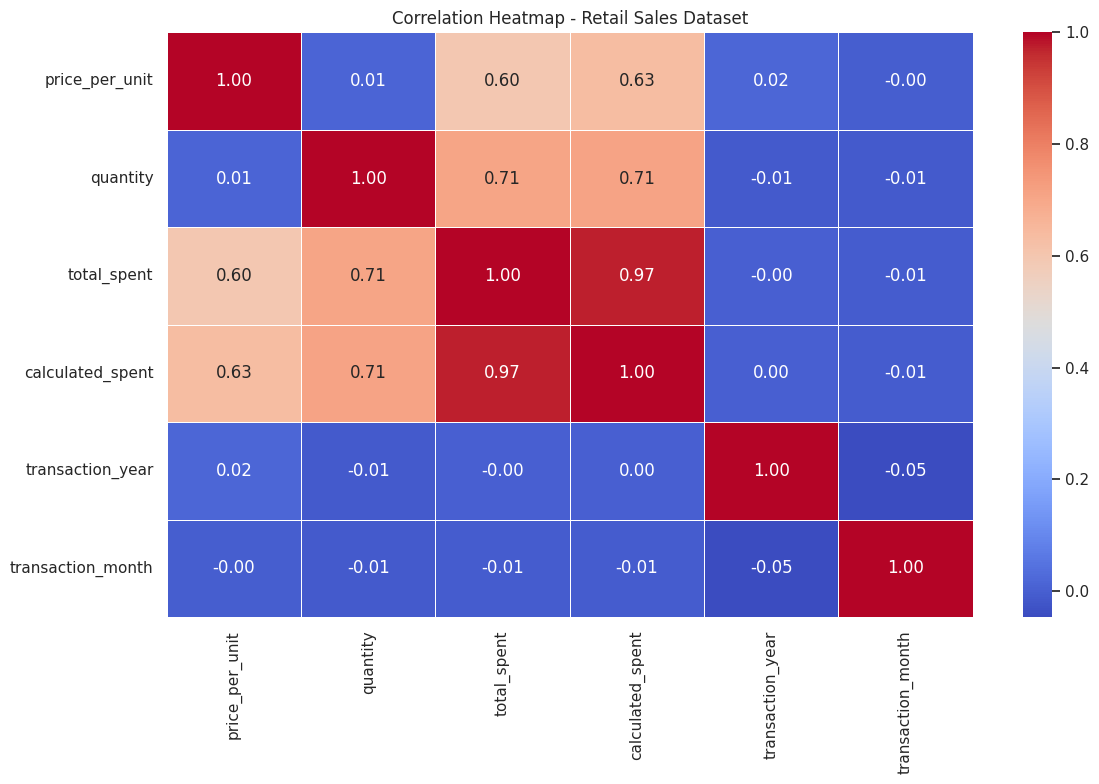

In [42]:

# TASK 04: Correlation Heatmap

numeric_df = df.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - Retail Sales Dataset")
plt.tight_layout()
plt.show()


In [43]:

# TASK 04: Inspect columns for hypothesis testing

print("Available columns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))


Available columns:
['transaction_id', 'customer_id', 'category', 'item', 'price_per_unit', 'quantity', 'total_spent', 'payment_method', 'location', 'transaction_date', 'discount_applied', 'calculated_spent', 'transaction_year', 'transaction_month']

Data types:


,Data Type
transaction_id,object
customer_id,object
category,object
item,object
price_per_unit,float64
quantity,float64
total_spent,float64
payment_method,object
location,object
transaction_date,object


In [44]:

print(df.columns.tolist())


['transaction_id', 'customer_id', 'category', 'item', 'price_per_unit', 'quantity', 'total_spent', 'payment_method', 'location', 'transaction_date', 'discount_applied', 'calculated_spent', 'transaction_year', 'transaction_month']


In [45]:

# TASK 04: Three Business Hypothesis Tests

from scipy import stats
import pandas as pd

# Prepare numeric columns
df["total_spent"] = pd.to_numeric(df["total_spent"], errors="coerce")
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
df["price_per_unit"] = pd.to_numeric(df["price_per_unit"], errors="coerce")

print("HYPOTHESIS TESTING RESULTS")
print("=" * 50)

# TEST 1: Is quantity related to total spending?
test1 = df[["quantity", "total_spent"]].dropna()

r, p1 = stats.pearsonr(
    test1["quantity"],
    test1["total_spent"]
)

print("\nTest 1: Quantity vs Total Spending")
print("H0: There is no linear relationship.")
print("H1: There is a linear relationship.")
print(f"Correlation: {r:.3f}")
print(f"P-value: {p1:.6g}")
print("Result:", "Reject H0" if p1 < 0.05 else "Fail to reject H0")

# TEST 2: Does average spending differ by payment method?
payment_groups = [
    group["total_spent"].dropna()
    for _, group in df.groupby("payment_method")
]
payment_groups = [g for g in payment_groups if len(g) >= 2]

print("\nTest 2: Spending by Payment Method")
print("H0: All payment methods have equal mean spending.")
print("H1: At least one mean differs.")

if len(payment_groups) >= 2:
    f2, p2 = stats.f_oneway(*payment_groups)
    print(f"F-statistic: {f2:.3f}")
    print(f"P-value: {p2:.6g}")
    print("Result:", "Reject H0" if p2 < 0.05 else "Fail to reject H0")
else:
    print("Not enough payment-method groups to test.")

# TEST 3: Does average spending differ by product category?
category_groups = [
    group["total_spent"].dropna()
    for _, group in df.groupby("category")
]
category_groups = [g for g in category_groups if len(g) >= 2]

print("\nTest 3: Spending by Product Category")
print("H0: All product categories have equal mean spending.")
print("H1: At least one category mean differs.")

if len(category_groups) >= 2:
    f3, p3 = stats.f_oneway(*category_groups)
    print(f"F-statistic: {f3:.3f}")
    print(f"P-value: {p3:.6g}")
    print("Result:", "Reject H0" if p3 < 0.05 else "Fail to reject H0")
else:
    print("Not enough category groups to test.")


HYPOTHESIS TESTING RESULTS

Test 1: Quantity vs Total Spending
H0: There is no linear relationship.
H1: There is a linear relationship.
Correlation: 0.709
P-value: 0
Result: Reject H0

Test 2: Spending by Payment Method
H0: All payment methods have equal mean spending.
H1: At least one mean differs.
F-statistic: 0.702
P-value: 0.495476
Result: Fail to reject H0

Test 3: Spending by Product Category
H0: All product categories have equal mean spending.
H1: At least one category mean differs.
F-statistic: 5.841
P-value: 8.71995e-07
Result: Reject H0


In [46]:

# TASK 04: Top 5 Business Findings

print("TOP 5 BUSINESS FINDINGS")
print("=" * 50)

# 1. Best-selling product categories by spending
print("\n1. Revenue by Product Category")
display(
    df.groupby("category")["total_spent"]
      .sum()
      .sort_values(ascending=False)
      .head(5)
)

# 2. Most popular payment methods
print("\n2. Most Used Payment Methods")
display(df["payment_method"].value_counts().head(5))

# 3. Average spending by category
print("\n3. Average Spending by Category")
display(
    df.groupby("category")["total_spent"]
      .mean()
      .sort_values(ascending=False)
      .head(5)
)

# 4. Highest-spending locations
print("\n4. Highest-Spending Locations")
display(
    df.groupby("location")["total_spent"]
      .sum()
      .sort_values(ascending=False)
      .head(5)
)

# 5. Monthly spending trend
print("\n5. Monthly Spending Trend")
display(
    df.groupby(["transaction_year", "transaction_month"])["total_spent"]
      .sum()
      .sort_values(ascending=False)
      .head(5)
)


TOP 5 BUSINESS FINDINGS

1. Revenue by Product Category


,total_spent
category,
Butchers,215930.0
Electric household essentials,211951.0
Beverages,204751.0
Food,203600.5
Furniture,202471.0



2. Most Used Payment Methods


,count
payment_method,
Cash,4310
Digital Wallet,4144
Credit Card,4121



3. Average Spending by Category


,total_spent
category,
Butchers,137.710459
Electric household essentials,133.218730
Beverages,130.664327
Food,128.211902
Computers and electric accessories,128.036585



4. Highest-Spending Locations


,total_spent
location,
Online,822432.0
In-store,795173.0



5. Monthly Spending Trend


transaction_year  transaction_month
2022              1                    55298.5
2024              12                   50528.0
                  1                    50295.5
2023              1                    49246.0
2024              4                    48007.0
Name: total_spent, dtype: float64

## Conclusion

Exploratory Data Analysis (EDA) was performed on the retail dataset using Python, Pandas, NumPy, Matplotlib, and Seaborn.

Descriptive statistics were used to understand the distribution of numerical variables. Histograms, box plots, and a correlation heatmap helped identify patterns, potential outliers, and relationships between variables.

Three statistical hypothesis tests were performed to examine the relationship between quantity and total spending, differences in spending across payment methods, and differences in spending across product categories.

The analysis also examined revenue by product category, payment method popularity, average spending by category, spending by location, and monthly spending trends.

These findings can help support data-driven decisions in retail management. The statistical results should be interpreted using the actual test outputs and business context.